Title:** Phishing URL Detection Using Character-Level LSTM Neural Networks.**


Part 1: Import the required libraries

In [ ]:
# ============================================================
# CELL 1: INSTALL AND IMPORT LIBRARIES
# Project: Phishing URL Detection Using Character-Level LSTM
# ============================================================

# Install the UCI Machine Learning Repository dataset loader.
!pip -q install ucimlrepo

# Import Python libraries for data handling.
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import the UCI dataset loader.
from ucimlrepo import fetch_ucirepo

# Import functions for splitting the dataset and calculating metrics.
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Import TensorFlow and Keras for building the LSTM model.
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Dropout,
    SpatialDropout1D
)
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Keep the output cleaner.
warnings.filterwarnings("ignore")

# Set random seeds so results are more reproducible.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Display the installed TensorFlow version.
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
GPU available: False
Libraries imported successfully!


Part 2: Download and load the dataset

In [ ]:
# ============================================================
# CELL 2: DOWNLOAD AND LOAD THE PHIUSIIL DATASET
# ============================================================

# Download the PhiUSIIL Phishing URL Dataset from UCI.
dataset = fetch_ucirepo(id=967)

# Get the input features and target labels.
features = dataset.data.features.copy()
targets = dataset.data.targets.copy()

# Display available feature columns.
print("Feature columns:")
print(features.columns.tolist())

# Display available target columns.
print("\nTarget columns:")
print(targets.columns.tolist())

# Combine features and targets into one DataFrame.
df = pd.concat(
    [
        features.reset_index(drop=True),
        targets.reset_index(drop=True)
    ],
    axis=1
)

# Display the dataset dimensions.
print("\nDataset shape:", df.shape)

# Display the first five rows.
display(df.head())

# Display information about data types and missing values.
print("\nDataset information:")
df.info()

Feature columns:
['URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']

Target columns:
['label']

Dataset shape: (235795, 55)


,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,...,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,...,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,...,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,...,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,...,1,0,1,244,15,34,72,1,85,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 55 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         235795 non-null  object 
 1   URLLength                   235795 non-null  int64  
 2   Domain                      235795 non-null  object 
 3   DomainLength                235795 non-null  int64  
 4   IsDomainIP                  235795 non-null  int64  
 5   TLD                         235795 non-null  object 
 6   URLSimilarityIndex          235795 non-null  float64
 7   CharContinuationRate        235795 non-null  float64
 8   TLDLegitimateProb           235795 non-null  float64
 9   URLCharProb                 235795 non-null  float64
 10  TLDLength                   235795 non-null  int64  
 11  NoOfSubDomain               235795 non-null  int64  
 12  HasObfuscation              235795 non-null  int64

Part 3: Select URLs and create the correct labels

In [ ]:
# ============================================================
# CELL 3: SELECT URL TEXT AND PREPARE CLASS LABELS
# ============================================================

# Find the URL column without depending on capitalization.
url_candidates = [
    col for col in df.columns
    if col.strip().lower() == "url"
]

if not url_candidates:
    raise ValueError(
        "URL column not found. Check the feature columns printed in Cell 2."
    )

url_column = url_candidates[0]

# Find the target label column.
label_candidates = [
    col for col in targets.columns
    if col.strip().lower() == "label"
]

if not label_candidates:
    raise ValueError(
        "Label column not found. Check the target columns printed in Cell 2."
    )

label_column = label_candidates[0]

# Create a smaller DataFrame containing only URLs and labels.
data = pd.DataFrame({
    "url": df[url_column],
    "original_label": df[label_column]
})

# Remove rows where URL or label is missing.
data = data.dropna(subset=["url", "original_label"]).copy()

# Convert URLs to strings and remove surrounding whitespace.
data["url"] = data["url"].astype(str).str.strip()

# Remove empty URLs.
data = data[data["url"].str.len() > 0].copy()

# Convert original labels into numeric values.
data["original_label"] = pd.to_numeric(
    data["original_label"],
    errors="coerce"
)

data = data.dropna(subset=["original_label"]).copy()

# PhiUSIIL label mapping:
# Original label 0 = phishing.
# Original label 1 = legitimate.
# New label 1 = phishing.
# New label 0 = legitimate.
label_mapping = {0: 1, 1: 0}

# Check that the dataset uses the expected original labels.
observed_labels = set(data["original_label"].unique())

if not observed_labels.issubset(set(label_mapping.keys())):
    raise ValueError(
        f"Unexpected labels found: {observed_labels}. "
        "Verify the dataset's label definitions before training."
    )

data["label"] = data["original_label"].map(label_mapping).astype(int)

# Remove exact duplicate URLs to reduce the chance of data leakage.
data = data.drop_duplicates(subset=["url"]).reset_index(drop=True)

# Show the number of examples in each class.
print("Selected URL column:", url_column)
print("Selected label column:", label_column)
print("\nTotal unique URLs:", len(data))

print("\nClass distribution:")
print(data["label"].map({
    0: "Legitimate",
    1: "Phishing"
}).value_counts())

# Display some example URLs and their converted labels.
display(data[["url", "label"]].head(10))

Selected URL column: URL
Selected label column: label

Total unique URLs: 235370

Class distribution:
label
Legitimate    134850
Phishing      100520
Name: count, dtype: int64


,url,label
0,https://www.southbankmosaics.com,0
1,https://www.uni-mainz.de,0
2,https://www.voicefmradio.co.uk,0
3,https://www.sfnmjournal.com,0
4,https://www.rewildingargentina.org,0
5,https://www.globalreporting.org,0
6,https://www.saffronart.com,0
7,https://www.nerdscandy.com,0
8,https://www.hyderabadonline.in,0
9,https://www.aap.org,0


Part 4: Explore and visualize the dataset

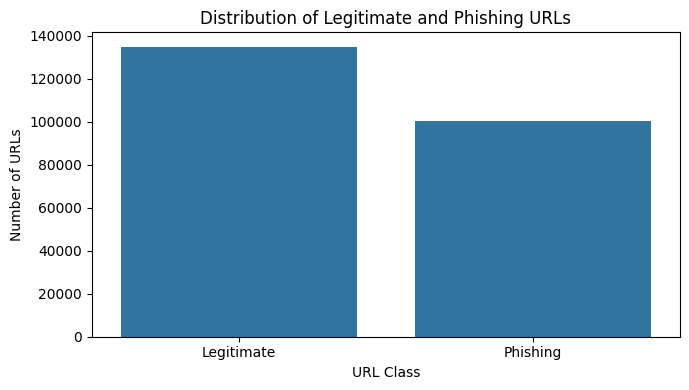

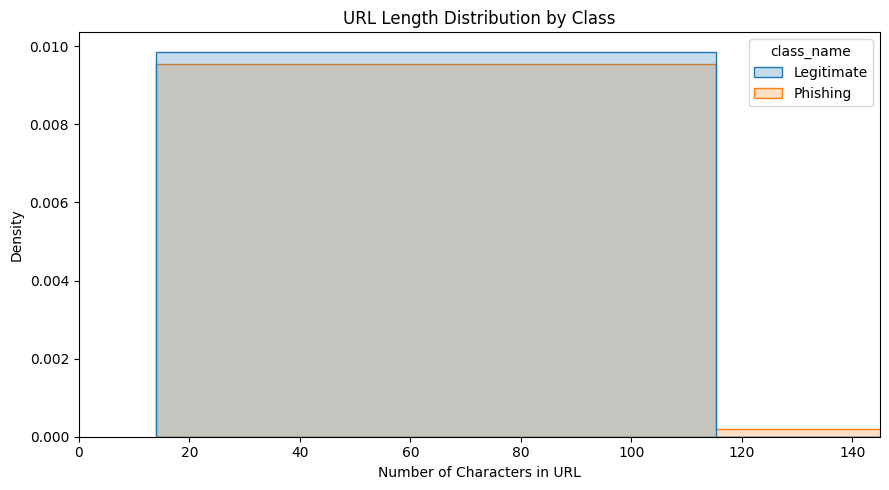

URL length statistics:


,count,mean,std,min,25%,50%,75%,max
class_name,,,,,,,,
Legitimate,134850.0,27.23,4.82,16.0,24.0,27.0,30.0,58.0
Phishing,100520.0,46.22,61.18,14.0,26.0,34.0,48.0,6097.0



Example phishing URLs:


,url
11,http://www.teramill.com
20,http://www.f0519141.xsph.ru
21,http://www.shprakserf.gq
27,https://service-mitld.firebaseapp.com/
28,http://www.kuradox92.lima-city.de



Example legitimate URLs:


,url
0,https://www.southbankmosaics.com
1,https://www.uni-mainz.de
2,https://www.voicefmradio.co.uk
3,https://www.sfnmjournal.com
4,https://www.rewildingargentina.org


In [ ]:
# ============================================================
# CELL 4: EXPLORATORY DATA ANALYSIS
# ============================================================

# Create readable class names for visualization.
data["class_name"] = data["label"].map({
    0: "Legitimate",
    1: "Phishing"
})

# Plot the number of URLs in each class.
plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x="class_name",
    order=["Legitimate", "Phishing"]
)

plt.title("Distribution of Legitimate and Phishing URLs")
plt.xlabel("URL Class")
plt.ylabel("Number of URLs")
plt.tight_layout()
plt.show()

# Calculate URL length.
data["url_length"] = data["url"].str.len()

# Plot URL lengths, limiting the x-axis to improve readability.
plt.figure(figsize=(9, 5))

sns.histplot(
    data=data,
    x="url_length",
    hue="class_name",
    bins=60,
    element="step",
    stat="density",
    common_norm=False
)

plt.xlim(0, data["url_length"].quantile(0.99))
plt.title("URL Length Distribution by Class")
plt.xlabel("Number of Characters in URL")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

# Print basic URL length statistics.
print("URL length statistics:")
display(
    data.groupby("class_name")["url_length"]
    .describe()
    .round(2)
)

# Display examples from both classes.
print("\nExample phishing URLs:")
display(data[data["label"] == 1]["url"].head(5))

print("\nExample legitimate URLs:")
display(data[data["label"] == 0]["url"].head(5))

Part 5: Prepare the training dataset

In [ ]:
# ============================================================
# CELL 5: PREPARE DATA FOR DEEP LEARNING
# ============================================================

# Limit the number of examples to make the notebook manageable.
# Set this to None if you want to use the entire dataset.
MAX_SAMPLES = 100000

# Sample rows while preserving the original class proportions.
if MAX_SAMPLES is not None and len(data) > MAX_SAMPLES:
    model_data = (
        data.groupby("label", group_keys=False)
        .apply(
            lambda group: group.sample(
                n=max(
                    1,
                    round(MAX_SAMPLES * len(group) / len(data))
                ),
                random_state=SEED
            )
        )
        .reset_index(drop=True)
    )

    # If rounding results in slightly more than the requested maximum,
    # take a stratified sample of exactly MAX_SAMPLES rows.
    if len(model_data) > MAX_SAMPLES:
        model_data, _ = train_test_split(
            model_data,
            train_size=MAX_SAMPLES,
            stratify=model_data["label"],
            random_state=SEED
        )
else:
    model_data = data.copy()

# Extract the raw URLs and their labels.
X_text = model_data["url"].astype(str).to_numpy()
y = model_data["label"].to_numpy(dtype=np.int32)

# Set the maximum number of characters in a URL.
MAX_LEN = 200

# Build a character vocabulary using the training data only.
# ID 0 is reserved for padding.
# ID 1 is reserved for unknown characters.
char_vocab = sorted(set("".join(X_text)))

char_to_id = {
    char: index + 2
    for index, char in enumerate(char_vocab)
}

VOCAB_SIZE = len(char_to_id) + 2

# Convert each URL into a sequence of character IDs.
def encode_url(url):
    """
    Convert a URL into a list of numerical character IDs.
    Unknown characters receive ID 1.
    """
    return [char_to_id.get(char, 1) for char in str(url)]

# Convert all URLs to sequences.
sequences = [encode_url(url) for url in X_text]

# Pad short sequences and truncate long sequences.
X = pad_sequences(
    sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

# Display the dimensions of the prepared data.
print("Number of URLs:", len(X))
print("Input shape:", X.shape)
print("Vocabulary size:", VOCAB_SIZE)
print("Maximum sequence length:", MAX_LEN)

# Display one example before and after numerical conversion.
print("\nOriginal URL:")
print(X_text[0])

print("\nEncoded sequence:")
print(encode_url(X_text[0])[:30])

print("\nPadded sequence:")
print(X[0][:30])

print("\nLabel:", y[0])
print("Label meaning:", "Phishing" if y[0] == 1 else "Legitimate")

Number of URLs: 100000
Input shape: (100000, 200)
Vocabulary size: 68
Maximum sequence length: 200

Original URL:
https://www.atelierozmoz.be

Encoded sequence:
[41, 53, 53, 49, 52, 26, 15, 15, 56, 56, 56, 14, 34, 53, 38, 45, 42, 38, 51, 48, 59, 46, 48, 59, 14, 35, 38]

Padded sequence:
[41 53 53 49 52 26 15 15 56 56 56 14 34 53 38 45 42 38 51 48 59 46 48 59
 14 35 38  0  0  0]

Label: 0
Label meaning: Legitimate


Part 6: Split the data into training, validation, and testing sets

In [ ]:
# ============================================================
# CELL 6: TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First, reserve 20% of the data for validation and testing.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Split the remaining 20% equally into validation and test sets.
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

# Display the size of each split.
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

# Display class proportions in each split.
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name} set:")
    print("Legitimate:", int(np.sum(labels == 0)))
    print("Phishing:", int(np.sum(labels == 1)))

Training samples: 80000
Validation samples: 10000
Testing samples: 10000

Training set:
Legitimate: 45834
Phishing: 34166

Validation set:
Legitimate: 5729
Phishing: 4271

Testing set:
Legitimate: 5730
Phishing: 4270


Part 7: Build the character-level LSTM model

In [ ]:
# ============================================================
# CELL 7: BUILD THE LSTM NEURAL NETWORK
# ============================================================

# Clear any previous Keras model from memory.
tf.keras.backend.clear_session()

# Create the model architecture.
model = Sequential([
    # Input is a sequence of character IDs.
    Input(shape=(MAX_LEN,), dtype="int32"),

    # Convert character IDs into learnable dense vectors.
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=32,
        mask_zero=True
    ),

    # Randomly drop complete embedding channels during training.
    SpatialDropout1D(0.2),

    # Learn sequential patterns from the character embeddings.
    LSTM(
        units=64,
        dropout=0.2,
        recurrent_dropout=0.0
    ),

    # Add a fully connected layer for further feature learning.
    Dense(32, activation="relu"),

    # Drop some activations during training to reduce overfitting.
    Dropout(0.3),

    # Output a probability that the URL is phishing.
    Dense(1, activation="sigmoid")
])

# Configure the model for binary classification.
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

# Display the model architecture and parameter counts.
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 32)        │         2,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 200, 32)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,121 (113.75 KB)

 Trainable params: 29,121 (113.75 KB)

 Non-trainable params: 0 (0.00 B)

Part 8: Train the LSTM model

In [ ]:
# ============================================================
# CELL 8: TRAIN THE LSTM MODEL
# ============================================================

# Stop training when validation loss stops improving.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
    verbose=1
)

# Reduce the learning rate when validation loss plateaus.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

# Train the model.
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("\nModel training completed.")

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 205s 324ms/step - accuracy: 0.9608 - auc: 0.9924 - loss: 0.0972 - val_accuracy: 0.9961 - val_auc: 0.9984 - val_loss: 0.0171 - learning_rate: 0.0010
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 305s 489ms/step - accuracy: 0.9960 - auc: 0.9978 - loss: 0.0207 - val_accuracy: 0.9975 - val_auc: 0.9982 - val_loss: 0.0152 - learning_rate: 0.0010
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 241s 359ms/step - accuracy: 0.9969 - auc: 0.9979 - loss: 0.0181 - val_accuracy: 0.9979 - val_auc: 0.9983 - val_loss: 0.0135 - learning_rate: 0.0010
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 204s 326ms/step - accuracy: 0.9969 - auc: 0.9978 - loss: 0.0181 - val_accuracy: 0.9979 - val_auc: 0.9984 - val_loss: 0.0128 - learning_rate: 0.0010
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.9973 - auc: 0.9980 - loss: 0.0158
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
625/625 ━━━━━━━━━━━━━━━━━━━━ 265s 332ms/step - accuracy: 0.9973 - auc:

Part 9: Visualize training performance

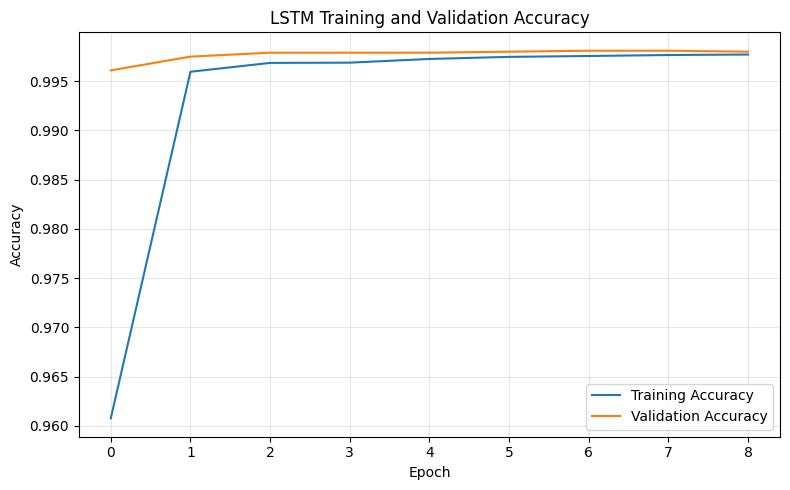

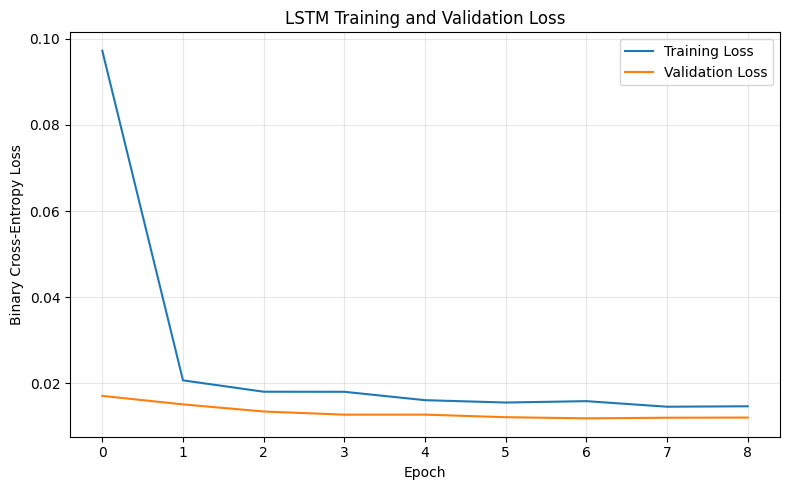

In [ ]:
# ============================================================
# CELL 9: PLOT TRAINING AND VALIDATION PERFORMANCE
# ============================================================

# Plot training and validation accuracy.
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot training and validation loss.
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Part 10: Evaluate the model on the test set

In [ ]:
# ============================================================
# CELL 10: MODEL EVALUATION
# ============================================================

# Predict phishing probabilities for the unseen test set.
y_probability = model.predict(
    X_test,
    batch_size=256,
    verbose=1
).ravel()

# Convert probabilities into class predictions.
# Threshold 0.5 means:
# Probability >= 0.5 -> Phishing (1)
# Probability < 0.5  -> Legitimate (0)
y_pred = (y_probability >= 0.5).astype(int)

# Calculate the evaluation metrics.
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, y_probability)

# Print the evaluation results.
print("=" * 55)
print("LSTM PHISHING URL DETECTION RESULTS")
print("=" * 55)

print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

# Display detailed performance for each class.
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    )
)

40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 192ms/step
LSTM PHISHING URL DETECTION RESULTS
Accuracy  : 0.9988 (99.88%)
Precision : 1.0000 (100.00%)
Recall    : 0.9972 (99.72%)
F1-score  : 0.9986
ROC-AUC   : 0.9991

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00      5730
    Phishing       1.00      1.00      1.00      4270

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



Part 11: Plot the confusion matrix

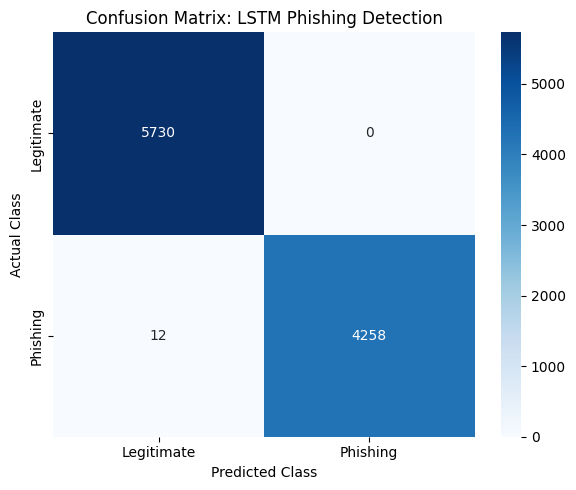

True negatives : 5730 (Legitimate correctly classified)
False positives: 0 (Legitimate incorrectly flagged)
False negatives: 12 (Phishing incorrectly missed)
True positives : 4258 (Phishing correctly detected)


In [ ]:
# ============================================================
# CELL 11: CONFUSION MATRIX
# ============================================================

# Calculate the confusion matrix.
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

# Display the matrix as a heatmap.
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.title("Confusion Matrix: LSTM Phishing Detection")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# Explain the four outcomes.
print("True negatives :", cm[0, 0], "(Legitimate correctly classified)")
print("False positives:", cm[0, 1], "(Legitimate incorrectly flagged)")
print("False negatives:", cm[1, 0], "(Phishing incorrectly missed)")
print("True positives :", cm[1, 1], "(Phishing correctly detected)")

Part 12: Plot the ROC curve

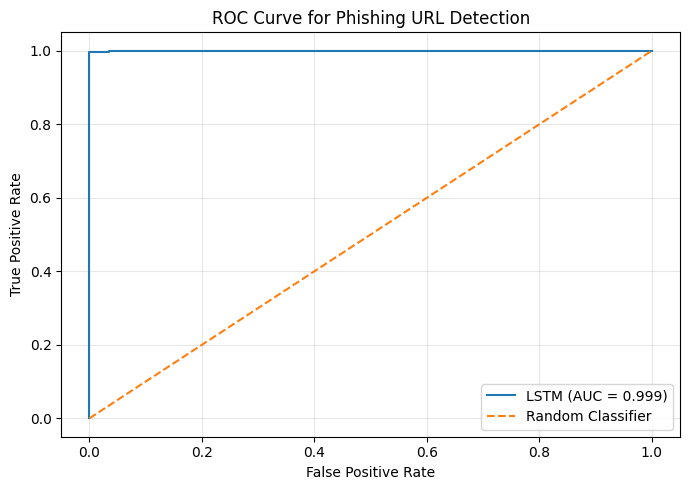

In [ ]:
# ============================================================
# CELL 12: ROC CURVE
# ============================================================

# Calculate the ROC curve points.
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

# Plot the ROC curve.
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"LSTM (AUC = {roc_auc:.3f})"
)

# A diagonal line represents random classification.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.title("ROC Curve for Phishing URL Detection")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Part 13: Create a function to predict new URLs

In [ ]:
# ============================================================
# CELL 13: PREDICT WHETHER A URL IS PHISHING
# ============================================================

def predict_url(url):
    """
    Predict whether a URL resembles phishing or legitimate URLs
    learned by the trained LSTM model.

    Parameters:
        url (str): The URL to classify.

    Returns:
        dict: Predicted class and estimated phishing probability.
    """

    # Validate the input.
    if not isinstance(url, str) or not url.strip():
        raise ValueError("Please enter a non-empty URL.")

    # Remove surrounding spaces.
    url = url.strip()

    # Convert the URL into character IDs.
    encoded_url = encode_url(url)

    # Pad or truncate it to the same length used during training.
    padded_url = pad_sequences(
        [encoded_url],
        maxlen=MAX_LEN,
        padding="post",
        truncating="post",
        value=0
    )

    # Get the model's phishing probability.
    phishing_probability = float(
        model.predict(padded_url, verbose=0)[0][0]
    )

    # Convert the probability to a binary prediction.
    if phishing_probability >= 0.5:
        prediction = "PHISHING"
    else:
        prediction = "LEGITIMATE"

    # Return both the classification and probability.
    result = {
        "url": url,
        "prediction": prediction,
        "phishing_probability": phishing_probability,
        "phishing_percentage": round(
            phishing_probability * 100, 2
        ),
        "threshold": 0.5
    }

    return result


# Example 1: Test a URL from a reserved example domain.
example_url_1 = "https://example.com/login"
result_1 = predict_url(example_url_1)

print("URL:", result_1["url"])
print("Prediction:", result_1["prediction"])
print(
    "Estimated phishing probability:",
    f'{result_1["phishing_percentage"]:.2f}%'
)

print("\n" + "-" * 50 + "\n")

# Example 2: Test another URL.
example_url_2 = "http://example.com/account/verify"
result_2 = predict_url(example_url_2)

print("URL:", result_2["url"])
print("Prediction:", result_2["prediction"])
print(
    "Estimated phishing probability:",
    f'{result_2["phishing_percentage"]:.2f}%'
)

URL: https://example.com/login
Prediction: PHISHING
Estimated phishing probability: 100.00%

--------------------------------------------------

URL: http://example.com/account/verify
Prediction: PHISHING
Estimated phishing probability: 100.00%


Test your own URL

In [ ]:
# ============================================================
# CELL 14: ENTER A URL MANUALLY
# ============================================================

# Enter the URL you want to test.
user_url = input("Enter a URL to check: ").strip()

# Predict the URL's class.
result = predict_url(user_url)

# Display the result.
print("\n========== URL DETECTION RESULT ==========")
print("URL:", result["url"])
print("Predicted class:", result["prediction"])
print(
    "Estimated phishing probability:",
    f'{result["phishing_percentage"]:.2f}%'
)
print("Classification threshold:", result["threshold"])

# Explain the result without claiming the URL is verified as safe.
if result["prediction"] == "PHISHING":
    print("The model flags this URL as potentially phishing.")
else:
    print("The model classifies this URL as legitimate-like.")

print(
    "\nNote: This is a model prediction, not a verified security verdict."
)

Enter a URL to check: https://www.futureskillsprime.in/

========== URL DETECTION RESULT ==========
URL: https://www.futureskillsprime.in/
Predicted class: PHISHING
Estimated phishing probability: 99.94%
Classification threshold: 0.5
The model flags this URL as potentially phishing.

Note: This is a model prediction, not a verified security verdict.


Part 15: Save the trained model

In [ ]:
# ============================================================
# CELL 15: SAVE THE MODEL AND CHARACTER VOCABULARY
# ============================================================

import json

# Create a directory for the saved project files.
os.makedirs("phishing_lstm_project", exist_ok=True)

# Save the trained neural network.
model_path = "phishing_lstm_project/phishing_lstm_model.keras"
model.save(model_path)

# Save the character vocabulary as a JSON file.
vocab_path = "phishing_lstm_project/character_vocabulary.json"

with open(vocab_path, "w", encoding="utf-8") as file:
    json.dump(char_to_id, file, ensure_ascii=True, indent=2)

# Save the preprocessing configuration.
config = {
    "max_length": MAX_LEN,
    "vocabulary_size": VOCAB_SIZE,
    "phishing_label": 1,
    "legitimate_label": 0,
    "classification_threshold": 0.5
}

config_path = "phishing_lstm_project/model_config.json"

with open(config_path, "w", encoding="utf-8") as file:
    json.dump(config, file, indent=2)

print("Model and preprocessing files saved successfully!")
print("Model:", model_path)
print("Vocabulary:", vocab_path)
print("Configuration:", config_path)

Model and preprocessing files saved successfully!
Model: phishing_lstm_project/phishing_lstm_model.keras
Vocabulary: phishing_lstm_project/character_vocabulary.json
Configuration: phishing_lstm_project/model_config.json


Part 16: Download the project files

In [ ]:
# ============================================================
# CELL 16: DOWNLOAD THE SAVED MODEL FILES
# ============================================================

# Create a ZIP archive containing all saved project files.
import shutil

zip_path = shutil.make_archive(
    "phishing_lstm_project",
    "zip",
    root_dir="phishing_lstm_project"
)

print("ZIP archive created:", zip_path)

# Download the ZIP archive to your computer.
from google.colab import files

files.download(zip_path)

ZIP archive created: /content/phishing_lstm_project.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Optional: Load the saved model later

In [ ]:
# ============================================================
# OPTIONAL CELL: LOAD A PREVIOUSLY SAVED MODEL
# ============================================================

import json
import tensorflow as tf

# Load the trained model.
loaded_model = tf.keras.models.load_model(
    "phishing_lstm_project/phishing_lstm_model.keras"
)

# Load the character vocabulary.
with open(
    "phishing_lstm_project/character_vocabulary.json",
    "r",
    encoding="utf-8"
) as file:
    loaded_char_to_id = json.load(file)

# Load preprocessing settings.
with open(
    "phishing_lstm_project/model_config.json",
    "r",
    encoding="utf-8"
) as file:
    loaded_config = json.load(file)

# Define the prediction function for the loaded model.
def predict_with_saved_model(url):
    if not isinstance(url, str) or not url.strip():
        raise ValueError("Please enter a non-empty URL.")

    # Convert characters using the saved vocabulary.
    sequence = [
        int(loaded_char_to_id.get(char, 1))
        for char in url.strip()
    ]

    # Apply the same padding and truncation used during training.
    padded = pad_sequences(
        [sequence],
        maxlen=loaded_config["max_length"],
        padding="post",
        truncating="post",
        value=0
    )

    # Generate a phishing probability.
    probability = float(
        loaded_model.predict(padded, verbose=0)[0][0]
    )

    # Return the prediction and probability.
    return {
        "url": url,
        "prediction": (
            "PHISHING"
            if probability >= loaded_config["classification_threshold"]
            else "LEGITIMATE"
        ),
        "phishing_probability": round(probability, 4)
    }


# Test the loaded model.
print(
    predict_with_saved_model("https://example.com/login")
)

{'url': 'https://example.com/login', 'prediction': 'PHISHING', 'phishing_probability': 1.0}
